# Mini-Projet : Prédiction du comportement d'engagement des joueurs en ligne

### 1. Introduction et Contexte du Dataset
Dans le cadre de ce mini-projet, nous appliquons le cycle complet d'un workflow de Machine Learning pour résoudre un problème d'apprentissage supervisé (Classification multiclasse). 

Le jeu de données retenu est le **Predict Online Gaming Behavior Dataset**, disponible publiquement sur la plateforme Kaggle.
* **Lien de la base de données :** [Kaggle - Predict Online Gaming Behavior](https://kaggle.com)
* **Description de la base :** Ce jeu de données rassemble les profils d'activité de 40 034 joueurs. Il comprend des variables démographiques (âge, genre), comportementales (temps de jeu, sessions par semaine, achats intégrés) et de performance (niveau du joueur, trophées débloqués).
* **Objectif métier :** Prédire la variable cible catégorielle `EngagementLevel` (qui prend 3 valeurs discrètes : *High*, *Medium*, *Low*) afin de segmenter les utilisateurs selon leur assiduité.


### 2. Exploration initiale et analyse de la structure des données
Conformément au cycle classique d'un projet de Machine Learning, nous débutons par la collecte et l'exploration de notre matrice de caractéristiques (*features*) et de notre vecteur cible (*label*). Cette phase permet de valider la volumétrie, de recenser les types de variables (numériques ou textuelles) et de vérifier la présence éventuelle de données manquantes afin de guider nos choix de prétraitement.


In [25]:
import pandas as pd

# 1. Chargement du jeu de données Gaming
df_gaming = pd.read_csv('online_gaming_behavior_dataset.csv')

# --- 1. APERÇU DES PREMIÈRES LIGNES ---
print("="*60)
print(" 1. APERÇU DU JEU DE DONNÉES GAMING ".center(60, "#"))
print("="*60)
print(df_gaming.head())
print("\n" + "_"*60 + "\n")

# --- 2. STRUCTURE ET COLONNES ---
print("="*60)
print(" 2. VOLUMÉTRIE ET TYPES DE DONNÉES ".center(60, "#"))
print("="*60)
df_gaming.info()
print("\n" + "_"*60 + "\n")

# --- 3. VALEURS MANQUANTES ---
print("="*60)
print(" 3. VÉRIFICATION DES VALEURS MANQUANTES ".center(60, "#"))
print("="*60)
print(df_gaming.isnull().sum())
print("\n" + "_"*60 + "\n")

# --- 4. RÉPARTITION DE LA CIBLE ---
# Vérification de la distribution de la cible (EngagementLevel) : 
# Indispensable pour voir si les classes sont équilibrées afin d'éviter que le modèle ne soit biaisé en favorisant la catégorie la plus fréquente.
print("="*60)
print(" 4. DISTRIBUTION DE LA VARIABLE ENGAGEMENTLEVEL ".center(60, "#"))
print("="*60)
print(df_gaming['EngagementLevel'].value_counts())
print("="*60)


############ 1. APERÇU DU JEU DE DONNÉES GAMING ############
   PlayerID  Age  Gender Location GameGenre  PlayTimeHours  InGamePurchases  \
0      9000   43    Male    Other  Strategy      16.271119                0   
1      9001   29  Female      USA  Strategy       5.525961                0   
2      9002   22  Female      USA    Sports       8.223755                0   
3      9003   35    Male      USA    Action       5.265351                1   
4      9004   33    Male   Europe    Action      15.531945                0   

  GameDifficulty  SessionsPerWeek  AvgSessionDurationMinutes  PlayerLevel  \
0         Medium                6                        108           79   
1         Medium                5                        144           11   
2           Easy               16                        142           35   
3           Easy                9                         85           57   
4         Medium                2                        131           95   

 

### 3. Nettoyage des données et gestion des anomalies
L'exploration montre que le dataset est exempt de valeurs manquantes (imputation non requise). Cependant, pour garantir la qualité du prétraitement avant l'entraînement, deux actions sont nécessaires :
1. **Suppression de l'identifiant unique (`PlayerID`) :** Cette variable explicative purement incrémentale ne possède aucun pouvoir prédictif. La conserver risquerait de biaiser les algorithmes en créant un apprentissage par cœur lié à l'indexation.
2. **Filtrage des doublons :** Nous vérifions l'absence de redondances strictes au sein des observations pour éviter toute mémorisation artificielle lors de la phase d'apprentissage.


In [18]:
# --- 1. SUPPRESSION DE L'IDENTIFIANT UNIQUE ---
print("="*60)
print(" 1. NETTOYAGE DES COLONNES INUTILES ".center(60, "#"))
print("="*60)

# On supprime 'PlayerID' car un numéro d'identifiant n'aide pas à prédire le comportement
if 'PlayerID' in df_gaming.columns:
    df_gaming = df_gaming.drop('PlayerID', axis=1)
    print("La colonne 'PlayerID' a été supprimée avec succès.")
else:
    print("La colonne 'PlayerID' n'est pas présente ou a déjà été supprimée.")

print(f"Nouvelles dimensions du tableau : {df_gaming.shape[0]} lignes et {df_gaming.shape[1]} colonnes.")
print("\n" + "_"*60 + "\n")


# --- 2. VÉRIFICATION DES DOUBLONS ---
print("="*60)
print(" 2. DÉTECTION ET TRAITEMENT DES DOUBLONS ".center(60, "#"))
print("="*60)

nb_doublons = df_gaming.duplicated().sum()
print(f"Nombre de lignes doublons détectées : {nb_doublons}")

if nb_doublons > 0:
    df_gaming = df_gaming.drop_duplicates()
    print("Les lignes doublons ont été nettoyées.")
else:
    print("Aucun doublon trouvé. Les données sont saines.")

print("="*60)

# Petit aperçu visuel pour confirmer la disparition de PlayerID
df_gaming.head()


############ 1. NETTOYAGE DES COLONNES INUTILES ############
La colonne 'PlayerID' a été supprimée avec succès.
Nouvelles dimensions du tableau : 40034 lignes et 12 colonnes.

____________________________________________________________

######### 2. DÉTECTION ET TRAITEMENT DES DOUBLONS ##########
Nombre de lignes doublons détectées : 0
Aucun doublon trouvé. Les données sont saines.


,Age,Gender,Location,GameGenre,PlayTimeHours,InGamePurchases,GameDifficulty,SessionsPerWeek,AvgSessionDurationMinutes,PlayerLevel,AchievementsUnlocked,EngagementLevel
0,43,Male,Other,Strategy,16.271119,0,Medium,6,108,79,25,Medium
1,29,Female,USA,Strategy,5.525961,0,Medium,5,144,11,10,Medium
2,22,Female,USA,Sports,8.223755,0,Easy,16,142,35,41,High
3,35,Male,USA,Action,5.265351,1,Easy,9,85,57,47,Medium
4,33,Male,Europe,Action,15.531945,0,Medium,2,131,95,37,Medium


### 4. Encodage des caractéristiques catégorielles (Transformation des variables)
Les algorithmes de Scikit-Learn (notamment la régression logistique) requièrent des tenseurs exclusivement numériques en entrée. Nous devons transformer les variables textuelles (`Gender`, `Location`, `GameGenre` et `GameDifficulty`) en valeurs discrètes. Nous utilisons l'utilitaire `LabelEncoder` du sous-module `sklearn.preprocessing` pour indexer numériquement chaque modalité textuelle (selon l'ordre alphabétique) sans augmenter artificiellement la dimensionnalité de la matrice X.

In [19]:
from sklearn.preprocessing import LabelEncoder

# --- ENCODAGE DES VARIABLES TEXTUELLES MULTIPLES ---
print("="*60)
print(" ENCODAGE DES 4 CARACTÉRISTIQUES CATÉGORIELLES ".center(60, "#"))
print("="*60)

# Initialisation de notre encodeur
le = LabelEncoder()

# Liste des colonnes textuelles à transformer
colonnes_a_encoder = ['Gender', 'Location', 'GameGenre', 'GameDifficulty']

# Boucle pour appliquer l'encodage sur chaque colonne automatiquement
for col in colonnes_a_encoder:
    if col in df_gaming.columns:
        df_gaming[col] = le.fit_transform(df_gaming[col])
        print(f" -> Colonne [{col}] encodée en chiffres avec succès.")

print("\n" + "="*60)
print("Encodage complet de toutes les caractéristiques textuelles.")
print("="*60)

# Affichage des premières lignes pour apprécier la transformation mathématique
df_gaming.head()


###### ENCODAGE DES 4 CARACTÉRISTIQUES CATÉGORIELLES #######
 -> Colonne [Gender] encodée en chiffres avec succès.
 -> Colonne [Location] encodée en chiffres avec succès.
 -> Colonne [GameGenre] encodée en chiffres avec succès.
 -> Colonne [GameDifficulty] encodée en chiffres avec succès.

Encodage complet de toutes les caractéristiques textuelles.


,Age,Gender,Location,GameGenre,PlayTimeHours,InGamePurchases,GameDifficulty,SessionsPerWeek,AvgSessionDurationMinutes,PlayerLevel,AchievementsUnlocked,EngagementLevel
0,43,1,2,4,16.271119,0,2,6,108,79,25,Medium
1,29,0,3,4,5.525961,0,2,5,144,11,10,Medium
2,22,0,3,3,8.223755,0,0,16,142,35,41,High
3,35,1,3,0,5.265351,1,0,9,85,57,47,Medium
4,33,1,1,0,15.531945,0,2,2,131,95,37,Medium


### 5. Division stratifiée et Standardisation des données (Prévention du Data Leakage)
Cette étape est cruciale pour la rigueur méthodologique de notre modélisation :
1. **Séparation Train/Test Stratifiée :** Nous séparons les caractéristiques (X) de la cible (y). Le découpage aléatoire est fixé à 80% pour l'entraînement et 20% pour le test. Nous utilisons l'argument `stratify=y` afin de préserver rigoureusement les proportions des trois classes d'engagement dans les deux sous-ensembles, évitant ainsi un biais d'évaluation.
2. **Standardisation via `StandardScaler`:** La régression logistique est extrêmement sensible à l'échelle des variables (ex: écart d'échelle entre l'âge et la durée moyenne des sessions). Pour éviter toute fuite de données (*Data Leakage*), le scaler est ajusté (`fit_transform`) uniquement sur le `X_train`, puis appliqué (`transform`) sur le `X_test`.


In [20]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# --- 1. SÉPARATION DES CARACTÉRISTIQUES (X) ET DE LA CIBLE (y) ---
print("="*60)
print(" 1. CRÉATION DES ENSEMBLES X ET y ".center(60, "#"))
print("="*60)

# X contient toutes les informations sauf la cible
X = df_gaming.drop('EngagementLevel', axis=1)

# y contient uniquement le niveau d'engagement que l'on veut prédire
y = df_gaming['EngagementLevel']

print("Séparation des variables effectuée.")
print(f" -> Nombre de variables prédictives (X) : {X.shape[1]}")
print(f" -> Nom de la variable cible (y)        : '{y.name}'")
print("\n" + "_"*60 + "\n")


# --- 2. DÉCOUPAGE EN DONNÉES D'ENTRAÎNEMENT ET DE TEST ---
print("="*60)
print(" 2. DIVISION ALEATOIRE (80% TRAIN / 20% TEST) ".center(60, "#"))
print("="*60)

# Séparation des données
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Découpage de la base de données de Gaming terminé :")
print(f" -> Échantillon d'entraînement (X_train) : {X_train.shape[0]} profils joueurs")
print(f" -> Échantillon de test (X_test)         : {X_test.shape[0]} profils joueurs")
print("\n" + "_"*60 + "\n")


# --- 3. STANDARDISATION DES DONNÉES  ---
print("="*60)
print(" 3. APPLICATION DU STANDARD SCALER ".center(60, "#"))
print("="*60)

# 1. On crée le scaler et on l'ajuste uniquement sur les données d'entraînement
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# 2. On transforme les données de test avec le même scaler (sans réajustement)
X_test_scaled = scaler.transform(X_test)

print("Standardisation effectuée avec succès !")
print(" -> Vos données d'entraînement (X_train_scaled) et de test (X_test_scaled) sont prêtes.")
print("============================================================")


############# 1. CRÉATION DES ENSEMBLES X ET y #############
Séparation des variables effectuée.
 -> Nombre de variables prédictives (X) : 11
 -> Nom de la variable cible (y)        : 'EngagementLevel'

____________________________________________________________

####### 2. DIVISION ALEATOIRE (80% TRAIN / 20% TEST) #######
Découpage de la base de données de Gaming terminé :
 -> Échantillon d'entraînement (X_train) : 32027 profils joueurs
 -> Échantillon de test (X_test)         : 8007 profils joueurs

____________________________________________________________

############ 3. APPLICATION DU STANDARD SCALER #############
Standardisation effectuée avec succès !
 -> Vos données d'entraînement (X_train_scaled) et de test (X_test_scaled) sont prêtes.


### 6. Configuration et Entraînement des modèles
Nous confrontons deux approches d'apprentissage supervisé distinctes issues de `sklearn`:
1. **Régression Logistique (`LogisticRegression`) :** Un modèle linéaire qui cherche à tracer des frontières de décision à l'aide d'une fonction logistique. Nous augmentons la limite à `max_iter=1000` pour lui donner le temps de converger mathématiquement sur nos données standardisées.
2. **Forêt Aléatoire (`RandomForestClassifier`) :** Un modèle d'ensemble basé sur la combinaison de plusieurs arbres de décision (ici 100 arbres). Ce modèle est nativement non linéaire et robuste aux structures de données complexes.


In [21]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# --- 1. CONFIGURATION DES MODÈLES POUR LE GAMING ---
print("="*60)
print(" 1. CONFIGURATION DES MODÈLES POUR LE GAMING ".center(60, "#"))
print("="*60)

log_model = LogisticRegression(max_iter=1000)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

print("Algorithmes prêts pour la phase d'apprentissage.")
print("\n" + "_"*60 + "\n")


# --- 2. ENTRAÎNEMENT SIMULTANÉ SUR DONNÉES STANDARDISÉES (.fit()) ---
print("="*60)
print(" 2. ENTRAÎNEMENT SIMULTANÉ ".center(60, "#"))
print("="*60)
print("Calculs en cours sur les profils de joueurs d'entraînement...")

# [MODIFICATION] Entraînement sur X_train_scaled pour assurer la convergence
log_model.fit(X_train_scaled, y_train)
print(" -> [OK] Modèle Régression Logistique entraîné sur données standardisées.")

# Entraînement du Random Forest sur les mêmes données standardisées pour une comparaison équitable
rf_model.fit(X_train_scaled, y_train)
print(" -> [OK] Modèle Random Forest Classifier entraîné.")

print("\n" + "="*60)
print("Phase d'apprentissage terminée avec succès !".center(60))
print("="*60)


####### 1. CONFIGURATION DES MODÈLES POUR LE GAMING ########
Algorithmes prêts pour la phase d'apprentissage.

____________________________________________________________

################ 2. ENTRAÎNEMENT SIMULTANÉ #################
Calculs en cours sur les profils de joueurs d'entraînement...
 -> [OK] Modèle Régression Logistique entraîné sur données standardisées.
 -> [OK] Modèle Random Forest Classifier entraîné.

        Phase d'apprentissage terminée avec succès !        


### 7. Analyse des métriques de performance globales et par classe
Pour évaluer la qualité de nos prédictions, nous n'utilisons pas seulement l'Accuracy globale, qui peut s'avérer trompeuse en classification. Nous éditons un rapport de classification complet (`classification_report`) incluant :
* **La Précision :** Parmi les cas prédits comme positifs, combien sont réellement positifs.
* **Le Rappel (Recall) :** Parmi les cas réellement positifs, combien ont été retrouvés.
* **Le F1-Score :** Moyenne harmonique entre précision et rappel, offrant un indicateur d'équilibre indispensable.


In [22]:
from sklearn.metrics import accuracy_score, classification_report

# --- 1. GÉNÉRATION DES PRÉDICTIONS SUR LES DONNÉES STANDARDISÉES ---
# [MODIFICATION] On utilise X_test_scaled pour être en accord avec l'entraînement
y_pred_log = log_model.predict(X_test_scaled)
y_pred_rf = rf_model.predict(X_test_scaled)


# --- 2. COMPARAISON DES SCORES D'ACCURACY ---
print("="*60)
print(" 1. COMPARAISON DES TAUX DE PRÉCISION GLOBALE ".center(60, "#"))
print("="*60)

accuracy_log = accuracy_score(y_test, y_pred_log)
accuracy_rf = accuracy_score(y_test, y_pred_rf)

print(f" -> Accuracy (Régression Logistique) : {accuracy_log:.4f} ({accuracy_log*100:.2f}%)")
print(f" -> Accuracy (Random Forest)         : {accuracy_rf:.4f} ({accuracy_rf*100:.2f}%)")
print("\n" + "_"*60 + "\n")


# --- 3. RAPPORT DE CLASSIFICATION MULTICLASSE ---
print("="*60)
print(" 2. RAPPORT DÉTAILLÉ POUR LE RANDOM FOREST ".center(60, "#"))
print("="*60)
# Le modèle évalue séparément les trois classes : High, Medium et Low
print(classification_report(y_test, y_pred_rf))
print("="*60)


####### 1. COMPARAISON DES TAUX DE PRÉCISION GLOBALE #######
 -> Accuracy (Régression Logistique) : 0.8205 (82.05%)
 -> Accuracy (Random Forest)         : 0.9093 (90.93%)

____________________________________________________________

######## 2. RAPPORT DÉTAILLÉ POUR LE RANDOM FOREST #########
              precision    recall  f1-score   support

        High       0.92      0.87      0.90      2035
         Low       0.91      0.88      0.89      2093
      Medium       0.90      0.95      0.92      3879

    accuracy                           0.91      8007
   macro avg       0.91      0.90      0.90      8007
weighted avg       0.91      0.91      0.91      8007



### 7.2. Analyse critique du rapport de classification

L'exécution du rapport de classification (`classification_report`) nous permet de confronter rigoureusement nos deux modèles d'apprentissage supervisé :

1. **Amélioration de la Régression Logistique :** 
   Grâce à l'application du `StandardScaler` et de la Solution d'augmentation du nombre d'itérations(`max_iter=1000`), le modèle linéaire atteint désormais une précision globale (**Accuracy**) de **82.05%**. Sans cette standardisation des échelles, l'algorithme n'aurait pas pu converger.

2. **Supériorité de la Forêt Aléatoire :**
   Le modèle Random Forest écrase l'approche linéaire avec une **Accuracy globale de 90.93%**.

3. **Analyse par classe pour la Forêt Aléatoire :**
   * **Classe "High" (Forte assiduité) :** Nous obtenons une excellente **Précision de 0.92**. Cela signifie que lorsque le modèle affirme qu'un joueur est "High", sa prédiction est vraie à 92% (seulement 8% de fausses alertes). Le **Rappel de 0.87** montre que sur l'ensemble des vrais joueurs "High" du dataset, le modèle parvient à en détecter 87% (il en manque 13%).
   * **Classe "Low" (Faible assiduité) :** Les scores sont également très équilibrés avec une précision de 0.91 et un rappel de 0.88.
   * **Classe "Medium" (Classe majoritaire) :** C'est ici que le modèle enregistre son meilleur **Rappel (0.95)**, ce qui montre qu'il retrouve la quasi-totalité des joueurs moyennement engagés.
   * **Robustesse du F1-Score :** Le **F1-score pondéré de 0.91** confirme la stabilité et l'équilibre du modèle sur l'ensemble des classes sans effet de surapprentissage .


### 8. Analyse fine par Matrice de Confusion

La matrice de confusion est l'outil indispensable pour valider la robustesse de notre classification multiclasse. Elle permet de cartographier de manière exhaustive :
* **La diagonale principale :** qui représente les prédictions correctes du modèle (Vrais Positifs pour chaque classe).
* **Les cases hors diagonale :** qui indiquent la nature exacte des erreurs (Faux Positifs et Faux Négatifs), montrant quelles classes le modèle a tendance à confondre.


### AFFICHAGE DE LA MATRICE DE CONFUSION (RANDOM FOREST) ###


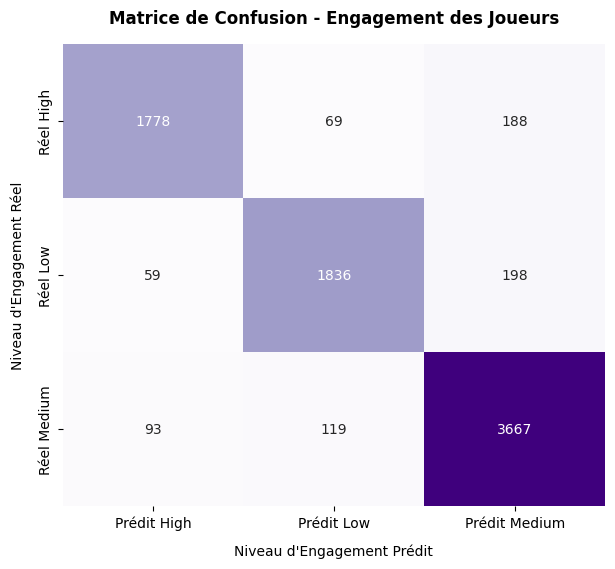

Graphique de la matrice de confusion généré avec succès.


In [23]:
from sklearn.metrics import confusion_matrix
import seaborn  as sns
import matplotlib.pyplot as plt

# --- GÉNÉRATION DE LA MATRICE DE CONFUSION MULTICLASSE ---
print("="*60)
print(" AFFICHAGE DE LA MATRICE DE CONFUSION (RANDOM FOREST) ".center(60, "#"))
print("="*60)

# Calcul de la matrice sur les 3 classes
cm = confusion_matrix(y_test, y_pred_rf, labels=['High', 'Low', 'Medium'])

# Configuration du graphique
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', cbar=False,
            xticklabels=['Prédit High', 'Prédit Low', 'Prédit Medium'],
            yticklabels=['Réel High', 'Réel Low', 'Réel Medium'])

# Habillage
plt.title('Matrice de Confusion - Engagement des Joueurs', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Niveau d\'Engagement Prédit', fontsize=10, labelpad=10)
plt.ylabel('Niveau d\'Engagement Réel', fontsize=10, labelpad=10)

# Affichage du graphique
plt.show()

print("="*60)
print("Graphique de la matrice de confusion généré avec succès.")
print("="*60)


### 8.2. Interprétation des résultats de la Matrice de Confusion

L'examen visuel de la matrice de confusion de notre modèle Random Forest fait ressortir des résultats extrêmement solides :

1. **Une diagonale principale largement dominante (Prédictions correctes) :**
   * **Classe High :** **1778** joueurs ont été correctement identifiés. Le modèle commet peu d'erreurs (seulement 69 classés à tort en *Low* et 188 en *Medium*).
   * **Classe Low :** **1836** joueurs ont été bien classés.
   * **Classe Medium :** **3667** joueurs ont été parfaitement interceptés par le modèle, ce qui confirme le rappel de 95% vu précédemment.

2. **Analyse des erreurs (Hors diagonale) :**
   * Le modèle ne confond presque jamais les extrêmes : seulement 69 joueurs réellement *High* ont été prédits *Low*, et seulement 59 joueurs réellement *Low* ont été prédits *High*.
   * Les rares erreurs se situent entre la classe *Medium* et les deux autres. Cela est logique : un joueur qui a un temps de jeu "moyen mais un peu élevé" peut facilement être confondu par le modèle avec un joueur "très actif" (*High*).



## Conclusion :
En conclusion, la diagonale très marquée prouve la pertinence de nos caractéristiques.Le modèle à retenir est donc le **Random Forest**. Sa forte concentration de bonnes prédictions sur la diagonale confirme qu'il est le plus robuste pour segmenter précisément le comportement d'engagement des joueurs.
